In [19]:
# merchant_risk_score	Pontuação de risco associada ao estabelecimento comercial.


In [20]:
import pandas as pd
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import roc_auc_score, confusion_matrix

In [21]:
FEATURES = ['proporcao_gasta_na_transacao', ]
NAME_CSV = "solved_08.csv"


In [22]:
df_test = pd.read_csv('data/test.csv')
df_train = pd.read_csv('data/train.csv')

In [23]:
def get_ids(df):
    return df['id']

In [ ]:
def feature_engenier(df_1, df_2):
    df = pd.concat([df_1, df_2], axis=0).drop(columns='id')

    # Relação entre o valor da transação e o saldo disponivel: vou criar uma coluna que varia de 0.0 até 1.0
    # amount_usd / account_balance_usd
    df['proporcao_gasta_na_transacao'] = df['amount_usd'] / df['account_balance_usd']
    df['reclamacoes_por_idade'] = df['prior_disputes'] / df['card_age_months'] * 100

    # prior_disputes	    Quantidade de contestações anteriores relacionadas ao cliente ou à sua atividade financeira. deve ser relacionado a idade do cartao (card_age_months)
    # prior_disputes / card_age_months
    df = df.drop(columns=['amount_usd', 'account_balance_usd', 'card_age_months'])
    return df

In [25]:
df = feature_engenier(df_train, df_test)
df['merchant_risk_score'].mean()

fraudes = df.loc[df['is_fraud'] == 1, 'reclamacoes_por_idade']
sem_fraudes = df.loc[df['is_fraud'] == 0, 'reclamacoes_por_idade']

In [26]:
def transform_data(df) -> pd.DataFrame:
    TARGET = 'is_fraud'
    targets = df[TARGET].reset_index()
    df = df.drop(columns=[TARGET])

    boolean_features = list(df.select_dtypes(['bool']).columns)
    string_features = list(df.select_dtypes(['string', 'object']).columns)
    numeric_features = list(df.select_dtypes(['number']).drop(columns=FEATURES).columns)

    boolean_features = df.select_dtypes(include='bool').columns

    for col in boolean_features:
        freq = df[col].value_counts()
        df[f'{col}_int'] = df[col].map(freq)

    df = df.drop(columns=boolean_features)

    preprocess = ColumnTransformer(
        transformers= [
            ("num", StandardScaler(), numeric_features),
            ("str", OneHotEncoder(handle_unknown='ignore', sparse_output=False), string_features)
        ],
        remainder='passthrough'
    )

    df = preprocess.fit_transform(df)
    names = preprocess.get_feature_names_out()
    df = pd.DataFrame(data=df, columns=names).reset_index()

    df = pd.concat([df, targets['is_fraud']], axis=1)
    
    return df

In [27]:
ids = get_ids(df_test)
df = feature_engenier(df_train, df_test)
df = transform_data(df).drop(columns=['index'])
df

,num__hours_since_last_txn,num__txn_count_last_24h,num__distance_from_home_km,num__customer_age,num__cvv_retry_count,num__velocity_score,num__time_of_day_hour,num__day_of_week,num__merchant_risk_score,num__prior_disputes,...,str__device_type_Windows PC,str__device_type_iPhone,remainder__proporcao_gasta_na_transacao,remainder__is_foreign_transaction_int,remainder__is_new_merchant_int,remainder__used_vpn_int,remainder__ip_country_mismatch_int,remainder__billing_shipping_mismatch_int,remainder__is_ai_generated_scam_attempt_int,is_fraud
0,0.497909,-1.323864,0.360545,0.255436,-0.295240,-1.236175,0.763141,0.010691,-0.476577,-0.401105,...,0.0,1.0,0.048182,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,0.0
1,-0.809496,0.010672,-0.045816,-1.309079,-0.295240,1.331491,1.636536,1.010526,-0.421138,2.218533,...,0.0,0.0,0.007680,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,0.0
2,-0.863508,0.677940,-0.466813,0.199561,-0.295240,1.552366,0.472009,-1.489062,-0.880484,-0.401105,...,0.0,0.0,0.006075,982628.0,847378.0,33555.0,983822.0,986964.0,996616.0,0.0
3,-0.239195,0.677940,-0.423766,-0.191568,-0.295240,0.162697,-0.692519,0.010691,0.529232,-0.401105,...,0.0,0.0,0.016883,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,0.0
4,-0.927051,0.677940,-0.163764,0.031934,-0.295240,1.460335,-1.129217,0.510609,1.012337,-0.401105,...,1.0,0.0,0.198675,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
999939,-0.342452,-1.991132,-0.418601,0.534814,3.160255,-1.539877,0.472009,-1.489062,-0.302342,-0.401105,...,0.0,0.0,0.053495,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,NaN
999940,-0.628398,1.345209,-1.065163,-0.694448,-0.295240,-0.067380,-1.129217,-1.489062,-0.555774,-0.401105,...,0.0,0.0,0.003025,982628.0,152566.0,966389.0,983822.0,986964.0,996616.0,NaN
999941,-0.361516,0.677940,1.885259,-1.364954,3.160255,1.064601,1.199839,-0.989145,0.584670,-0.401105,...,0.0,0.0,0.024900,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,NaN
999942,-0.777725,0.010672,0.281339,-1.309079,-0.295240,-0.720801,-1.274782,1.510444,0.046127,-0.401105,...,0.0,0.0,0.001034,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,NaN


In [28]:
df_train = df[:len(df_train)]
df_test = df[len(df_train):]
print(len(df_train), len(df_test))

699960 299984


In [29]:
x = df_train.drop(columns='is_fraud')
y = df_train['is_fraud']

x_train, x_temp, y_train, y_temp = train_test_split(x, y, test_size=0.3, shuffle=True, random_state=42, stratify=y)
x_val, x_test, y_val, y_test = train_test_split(x_temp, y_temp, test_size=0.5, shuffle=True, random_state=42, stratify=y_temp)

print(x_train.shape, x_val.shape, x_test.shape)

(489972, 53) (104994, 53) (104994, 53)


In [30]:
#params = {
#    'n_estimators': 1000,
#    'max_depth': 9,
#    'eval_metric': 'auc',
#    'learning_rate': 0.09918802139540925,
#    'subsample': 0.6684329833808584,
#    'colsample_bytree': 0.9151036654152414,
#    'gamma': 0.14911870890152207,
#    'reg_alpha': 0.10085071428350272,
#   'reg_lambda': 0.6724424529145199,
#    'min_child_weight': 2,
#    'n_jobs': -1,
#    'early_stopping_rounds': 10
#}

params = {
    'n_estimators': 724,
    'max_depth': 3,
    'eval_metric': 'auc',
    'learning_rate': 0.2765002250991,
    'subsample': 0.7510915544705179,
    'colsample_bytree': 0.8322176049375639,
    'gamma': 0.5830360486103,
    'reg_alpha': 0.9112447554108892,
    'reg_lambda': 0.5205603841967,
    'min_child_weight': 7,
    'n_jobs': 1,
    'early_stopping_rounds': 30
}

xgb_clf = XGBClassifier(**params)
xgb_clf.fit(x_train, y_train, eval_set = [(x_val, y_val)])

[0]	validation_0-auc:0.79641
[1]	validation_0-auc:0.86862
[2]	validation_0-auc:0.88529
[3]	validation_0-auc:0.90981
[4]	validation_0-auc:0.91415
[5]	validation_0-auc:0.91866
[6]	validation_0-auc:0.91983
[7]	validation_0-auc:0.92188
[8]	validation_0-auc:0.92267
[9]	validation_0-auc:0.92489
[10]	validation_0-auc:0.92491
[11]	validation_0-auc:0.92629
[12]	validation_0-auc:0.92716
[13]	validation_0-auc:0.92761
[14]	validation_0-auc:0.92934
[15]	validation_0-auc:0.93048
[16]	validation_0-auc:0.93155
[17]	validation_0-auc:0.93238
[18]	validation_0-auc:0.93275
[19]	validation_0-auc:0.93290
[20]	validation_0-auc:0.93307
[21]	validation_0-auc:0.93310
[22]	validation_0-auc:0.93307
[23]	validation_0-auc:0.93379
[24]	validation_0-auc:0.93428
[25]	validation_0-auc:0.93469
[26]	validation_0-auc:0.93499
[27]	validation_0-auc:0.93547
[28]	validation_0-auc:0.93574
[29]	validation_0-auc:0.93595
[30]	validation_0-auc:0.93617
[31]	validation_0-auc:0.93883
[32]	validation_0-auc:0.93892
[33]	validation_0-au

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8322176049375639
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",30
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


<Axes: >

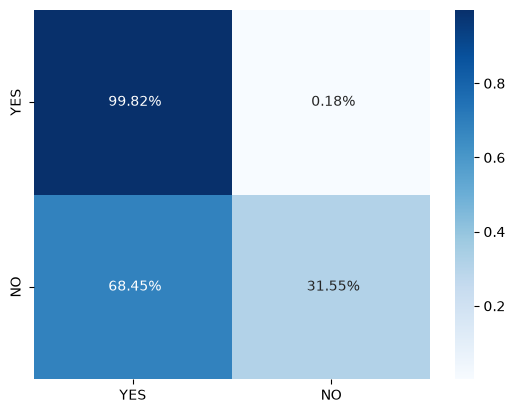

In [31]:
y_pred = xgb_clf.predict(x_test)
y_pred

cm = confusion_matrix(y_test, y_pred, normalize='true')

sns.heatmap(
    cm,
    cmap='Blues',
    fmt =" .2%",
    annot=True,
    xticklabels=["YES", "NO"],
    yticklabels=["YES", "NO"]
)

In [32]:
df_test = df_test.drop(columns=['is_fraud'])
out = xgb_clf.predict_proba(df_test)[:,1]
df_final = pd.DataFrame(
    {
        "id": ids,
        "is_fraud": out
    }
)

In [33]:
df_final.to_csv(NAME_CSV, index=False)

In [34]:
# kaggle competitions submit -c playground-series-s6e11 -f 2026_11_kaggle/solved_07.csv -m "feature engenier"

In [35]:
df_train

,num__hours_since_last_txn,num__txn_count_last_24h,num__distance_from_home_km,num__customer_age,num__cvv_retry_count,num__velocity_score,num__time_of_day_hour,num__day_of_week,num__merchant_risk_score,num__prior_disputes,...,str__device_type_Windows PC,str__device_type_iPhone,remainder__proporcao_gasta_na_transacao,remainder__is_foreign_transaction_int,remainder__is_new_merchant_int,remainder__used_vpn_int,remainder__ip_country_mismatch_int,remainder__billing_shipping_mismatch_int,remainder__is_ai_generated_scam_attempt_int,is_fraud
0,0.497909,-1.323864,0.360545,0.255436,-0.295240,-1.236175,0.763141,0.010691,-0.476577,-0.401105,...,0.0,1.0,0.048182,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,0.0
1,-0.809496,0.010672,-0.045816,-1.309079,-0.295240,1.331491,1.636536,1.010526,-0.421138,2.218533,...,0.0,0.0,0.007680,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,0.0
2,-0.863508,0.677940,-0.466813,0.199561,-0.295240,1.552366,0.472009,-1.489062,-0.880484,-0.401105,...,0.0,0.0,0.006075,982628.0,847378.0,33555.0,983822.0,986964.0,996616.0,0.0
3,-0.239195,0.677940,-0.423766,-0.191568,-0.295240,0.162697,-0.692519,0.010691,0.529232,-0.401105,...,0.0,0.0,0.016883,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,0.0
4,-0.927051,0.677940,-0.163764,0.031934,-0.295240,1.460335,-1.129217,0.510609,1.012337,-0.401105,...,1.0,0.0,0.198675,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
699955,-0.402819,0.010672,-0.891254,-1.141452,-0.295240,0.171900,-1.565914,0.010691,1.550880,-0.401105,...,1.0,0.0,0.447538,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,0.0
699956,-1.047784,2.012477,-0.433237,1.652325,3.160255,4.239672,-0.983651,-0.989145,0.687627,-0.401105,...,0.0,1.0,0.015018,982628.0,847378.0,966389.0,983822.0,986964.0,996616.0,0.0
699957,-0.261435,0.677940,-0.806021,0.981818,-0.295240,0.033854,-1.129217,1.510444,0.275800,-0.401105,...,0.0,0.0,0.023909,982628.0,847378.0,33555.0,983822.0,986964.0,996616.0,0.0
699958,-0.758662,0.677940,1.247307,1.149445,-0.295240,1.110617,0.035311,0.010691,-0.231064,-0.401105,...,1.0,0.0,0.010412,982628.0,847378.0,33555.0,983822.0,986964.0,996616.0,0.0
